In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, optimizers
import nibabel as nib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
import joblib

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Detected GPU: {gpus}")
    except RuntimeError as e:
        print(e)

TARGET_SHAPE_2D = (128, 128)
BATCH_SIZE = 62
EPOCHS = 20
LEARNING_RATE = 1e-4
SEED = 42

MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_CK7.csv"
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")
MODEL_SAVE_PATH = "/content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics.keras"
SCALER_SAVE_PATH = "/content/drive/MyDrive/Colab Notebooks/cnn_2d/radiomics_scaler.joblib"

print("TensorFlow version:", tf.__version__)

Detected GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow version: 2.19.0


In [ ]:
def load_ct_volume(ct_path):
    try:
        img = nib.load(ct_path)
        vol = img.get_fdata().astype(np.float32)
        vol = np.nan_to_num(vol)

        # (H, W, D) -> (H, W, D, 1)
        if len(vol.shape) == 3:
            vol = np.expand_dims(vol, axis=-1)
        return vol
    except Exception as e:
        print(f"Eroare la încărcarea {ct_path}: {e}")
        return None

def is_slice_informative(slice_2d, threshold=0.01, min_pixels=500):
    active_pixels = np.sum(slice_2d > threshold)
    return active_pixels > min_pixels

def load_radiomics_features(path):
    feats = {}
    if not os.path.exists(path):
        return None

    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            try:
                v_clean = v.strip().replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k.strip()] = val
            except:
                continue
    return feats

In [ ]:
df_labels = pd.read_csv(LABELS_CSV)
df_manifest = pd.read_csv(MANIFEST_CSV)

df_manifest.columns = [c.strip() for c in df_manifest.columns]

df_labels['Code'] = df_labels['Code'].astype(str).str.extract(r'(\d+)')[0]
if 'Code' in df_manifest.columns:
    df_manifest['Code'] = df_manifest['Code'].astype(str).str.extract(r'(\d+)')[0]

df_clean = df_labels.dropna(subset=['TTF1', 'CK7']).copy()
data_index = df_clean.merge(df_manifest, on='Code', how='inner')

def get_best_path(row):
    if 'ct_cropped_nifti_path' in row and pd.notna(row['ct_cropped_nifti_path']):
        return row['ct_cropped_nifti_path']
    elif 'ct_nifti_path' in row and pd.notna(row['ct_nifti_path']):
        return row['ct_nifti_path']
    return None

data_index['ct_path'] = data_index.apply(get_best_path, axis=1)
data_index['radiomics_path'] = data_index['Code'].apply(lambda x: str(RADIOMICS_DIR / f"{x}_radiomics.txt"))

data_index['files_exist'] = data_index.apply(lambda x: os.path.exists(str(x['ct_path'])) and os.path.exists(str(x['radiomics_path'])), axis=1)
data_index = data_index[data_index['files_exist']].reset_index(drop=True)

print(f"Total valid patients found: {len(data_index)}")

all_radiomics = []
valid_indices = []

for idx, row in data_index.iterrows():
    feats = load_radiomics_features(row['radiomics_path'])
    if feats:
        all_radiomics.append(list(feats.values()))
        valid_indices.append(idx)

data_index = data_index.iloc[valid_indices].reset_index(drop=True)
X_radio_raw = np.array(all_radiomics)

data_index['stratify_key'] = data_index['TTF1'].astype(str) + "_" + data_index['CK7'].astype(str)

train_df, test_df = train_test_split(data_index, test_size=0.1, stratify=data_index['stratify_key'], random_state=SEED)

train_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df['stratify_key'], random_state=SEED)

print("-" * 50)
print(f"Dataset Split Summary:")
print(f"Train set: {len(train_df)} patients")
print(f"Validation set: {len(val_df)} patients")
print(f"Test set: {len(test_df)} patients")
print("-" * 50)

print("\nPatients in VALIDATION set (IDs):")
print(val_df['Code'].values)

print("\nPatients in TEST set (IDs):")
print(test_df['Code'].values)
print("-" * 50)

scaler = StandardScaler()

train_indices = train_df.index.tolist()
X_train_raw = X_radio_raw[train_indices]

scaler.fit(X_train_raw)

joblib.dump(scaler, SCALER_SAVE_PATH)
print(f"\nRadiomics Scaler saved to: {SCALER_SAVE_PATH}")

X_radio_scaled = scaler.transform(X_radio_raw)

def prepare_arrays(df):
    indices = df.index.tolist()
    paths = df['ct_path'].tolist()
    radio = X_radio_scaled[indices]
    labels = df[['TTF1', 'CK7']].values
    return paths, radio, labels

train_paths, train_radio, train_labels = prepare_arrays(train_df)
val_paths, val_radio, val_labels = prepare_arrays(val_df)
test_paths, test_radio, test_labels = prepare_arrays(test_df)

Total valid patients found: 87
--------------------------------------------------
Dataset Split Summary:
Train set: 70 patients
Validation set: 8 patients
Test set: 9 patients
--------------------------------------------------

Patients in VALIDATION set (IDs):
['13111' '3111' '19111' '56111' '2011' '50011' '65111' '24111']

Patients in TEST set (IDs):
['25111' '45111' '42111' '89011' '33111' '36111' '55011' '80111' '48011']
--------------------------------------------------

Radiomics Scaler saved to: /content/drive/MyDrive/Colab Notebooks/cnn_2d/radiomics_scaler.joblib


In [ ]:
def slice_generator(ct_paths, X_radio, y_labels):
    num_patients = len(ct_paths)

    for i in range(num_patients):
        path = ct_paths[i]
        vol_3d = load_ct_volume(path)

        if vol_3d is None: continue

        radio_feats = X_radio[i]

        lbl_ttf1 = float(y_labels[i][0])
        lbl_ck7 = float(y_labels[i][1])

        depth = vol_3d.shape[2]

        for z in range(depth):
            slice_img = vol_3d[:, :, z, :]
            slice_resized = tf.image.resize(slice_img, TARGET_SHAPE_2D)

            slice_resized = slice_resized.numpy()

            if is_slice_informative(slice_resized[:, :, 0]):
                yield (slice_resized, radio_feats), {"TTF1": lbl_ttf1, "CK7": lbl_ck7}

def make_2d_dataset(ct_paths, X_radio, y, batch_size=32, shuffle=False):
    output_signature = (
        (
            tf.TensorSpec(shape=(128, 128, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "CK7": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: slice_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )

    if shuffle:
        ds = ds.shuffle(buffer_size=2000)

    def expand_labels(inputs, targets):
        return inputs, {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "CK7": tf.expand_dims(targets["CK7"], -1)
        }

    ds = ds.map(expand_labels, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.repeat()

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_2d_dataset(train_paths, train_radio, train_labels, BATCH_SIZE, shuffle=True)
val_ds = make_2d_dataset(val_paths, val_radio, val_labels, BATCH_SIZE, shuffle=False)

print("\nBatch dimensions:")
try:
    for (img, rad), lbl in train_ds.take(1):
        print("Image Batch Shape:", img.shape)
        print("Radiomics Batch Shape:", rad.shape)
        print("Labels TTF1 Shape:", lbl['TTF1'].shape)
        break
except Exception as e:
    print(f"Erorr: {e}")


Batch dimensions:
Image Batch Shape: (62, 128, 128, 1)
Radiomics Batch Shape: (62, 107)
Labels TTF1 Shape: (62, 1)


In [ ]:
def build_2d_efficientnet_model(radio_dim, input_shape=(128, 128, 1), learning_rate=1e-4):
    data_augmentation = tf.keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.05),
    ], name="augmentation")

    img_input = layers.Input(shape=input_shape, name="img_input")

    x = data_augmentation(img_input)
    x = layers.Rescaling(255.0)(x)

    x = layers.Conv2D(3, (3, 3), padding='same', use_bias=False)(x)

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(128, 128, 3)
    )

    base_model.trainable = True

    for layer in base_model.layers[:-20]:
        layer.trainable = False

    x = base_model(x)


    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)

    radio_input = layers.Input(shape=(radio_dim,), name="radio_input")

    r = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01))(radio_input)
    r = layers.BatchNormalization()(r)
    r = layers.Dropout(0.5)(r)

    combined = layers.Concatenate()([x, r])

    z = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.01))(combined)
    z = layers.Dropout(0.4)(z)

    out_ttf1 = layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_ck7 = layers.Dense(1, activation="sigmoid", name="CK7")(z)

    model = models.Model(inputs=[img_input, radio_input], outputs={"TTF1": out_ttf1, "CK7": out_ck7})

    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")],
            "CK7": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")]
        }
    )

    return model

radio_dim = X_radio_scaled.shape[1]
model = build_2d_efficientnet_model(radio_dim=radio_dim)
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 128, 128,  │          0 │ img_input[0][0]   │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 128, 128,  │          0 │ augmentation[0][… │
│ (Rescaling)         │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │         27 │ rescaling_6[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ conv2d_2[0][0]    │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio_input         │ (None, 107)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      6,912 │ radio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 1280)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 1344)      │          0 │ dropout_6[0][0],  │
│ (Concatenate)       │                   │            │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │     86,080 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CK7 (Dense)         │ (None, 1)         │         65 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TTF1 (Dense)        │ (None, 1)         │         65 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,148,096 (15.82 MB)

 Trainable params: 1,446,797 (5.52 MB)

 Non-trainable params: 2,701,299 (10.30 MB)

In [ ]:
def count_valid_slices(ct_paths):

    total = 0
    print(f"Counting valid slices for {len(ct_paths)} patients...")
    for path in ct_paths:
        try:
            vol = load_ct_volume(path)
            if vol is None: continue


            for z in range(vol.shape[2]):
                slice_img = vol[:, :, z]
                slice_resized = tf.image.resize(slice_img, TARGET_SHAPE_2D).numpy()

                if is_slice_informative(slice_resized[:, :, 0]):
                    total += 1
        except Exception as e:
            print(f"Error counting {path}: {e}")
    return total

print("--- Calculating Dataset Size ---")
num_train_slices = count_valid_slices(train_paths)
num_val_slices = count_valid_slices(val_paths)

print(f"Total Train Slices: {num_train_slices}")
print(f"Total Val Slices: {num_val_slices}")

TRAIN_STEPS = num_train_slices // BATCH_SIZE
VAL_STEPS = num_val_slices // BATCH_SIZE

print(f"Steps per Epoch: {TRAIN_STEPS}")
print(f"Validation Steps: {VAL_STEPS}")

--- Calculating Dataset Size ---
Counting valid slices for 70 patients...
Counting valid slices for 8 patients...
Total Train Slices: 3957
Total Val Slices: 440
Steps per Epoch: 63
Validation Steps: 7


In [ ]:
def train():
    callbacks = [
      tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
      tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1),
      tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_loss', save_best_only=True, verbose=1)
      ]
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        steps_per_epoch=TRAIN_STEPS,
        validation_steps=VAL_STEPS,
        callbacks=callbacks
    )

In [ ]:
train()

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - CK7_acc: 0.5038 - CK7_auc: 0.4983 - CK7_loss: 1.2251 - TTF1_acc: 0.5822 - TTF1_auc: 0.5083 - TTF1_loss: 0.9853 - loss: 4.2233
Epoch 1: val_loss improved from inf to 3.30259, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 274ms/step - CK7_acc: 0.5039 - CK7_auc: 0.4984 - CK7_loss: 1.2248 - TTF1_acc: 0.5825 - TTF1_auc: 0.5086 - TTF1_loss: 0.9847 - loss: 4.2219 - val_CK7_acc: 0.5300 - val_CK7_auc: 0.5316 - val_CK7_loss: 0.7010 - val_TTF1_acc: 0.6682 - val_TTF1_auc: 0.5631 - val_TTF1_loss: 0.6407 - val_loss: 3.3026 - learning_rate: 1.0000e-04
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - CK7_acc: 0.5498 - CK7_auc: 0.5459 - CK7_loss: 1.1026 - TTF1_acc: 0.6228 - TTF1_auc: 0.5894 - TTF1_loss: 0.8351 - loss: 3.8822
Epoch 2: val_loss improved from 3.30259 to 3.23082, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_ra


EVALUATION ON TEST SET (Patient-Level Aggregation)

>>> ANALIZĂ TTF1


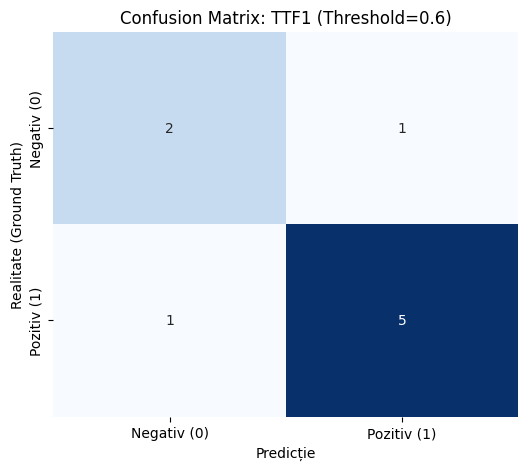

[TTF1] Acc: 0.7778 | F1: 0.8333


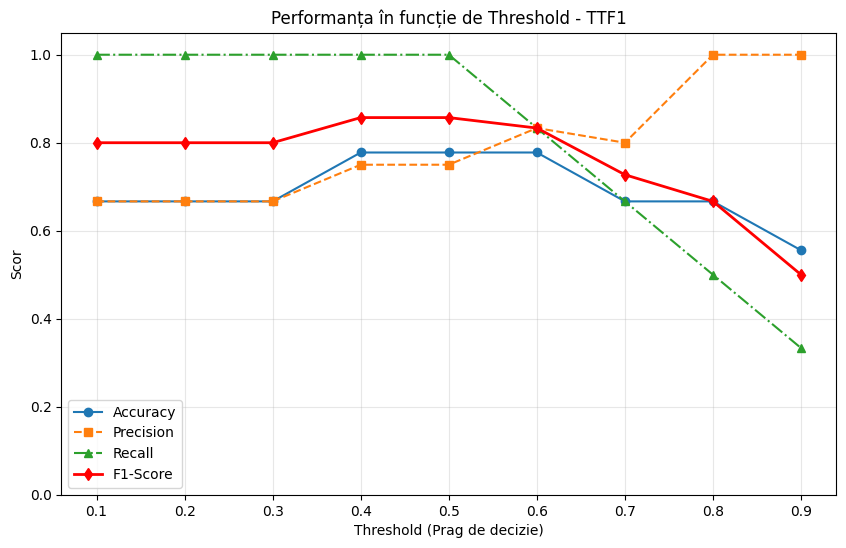


--------------------------------------------------

>>> ANALIZĂ CK7


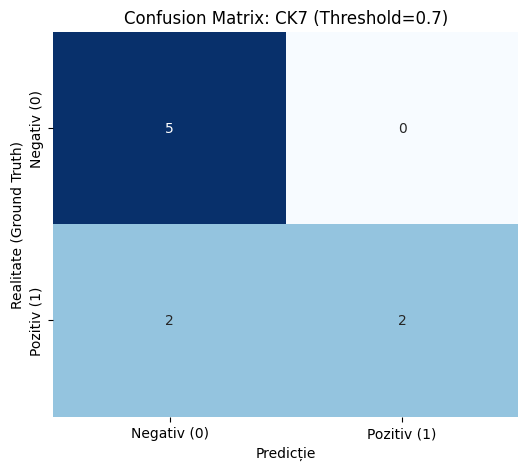

[CK7] Acc: 0.7778 | F1: 0.6667


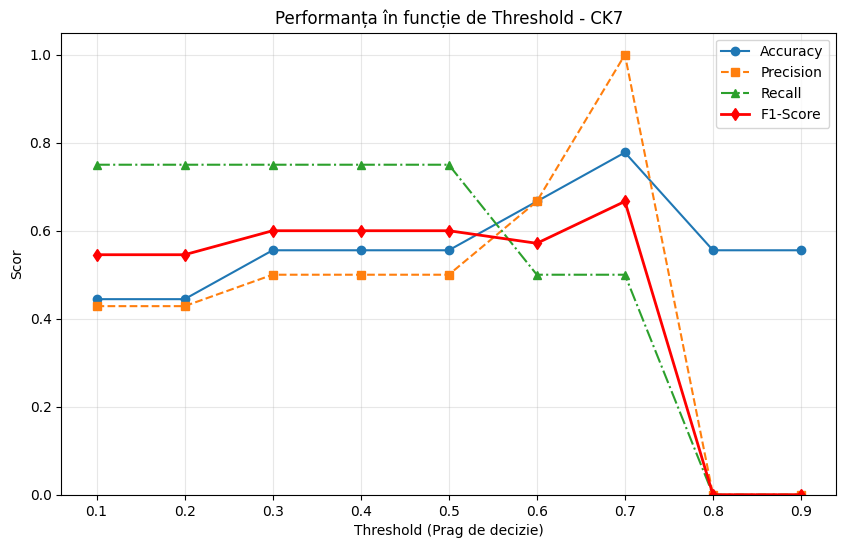

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

print("\n" + "="*50)
print("EVALUATION ON TEST SET (Patient-Level Aggregation)")
print("="*50)

y_true_ttf1 = []
y_prob_ttf1 = []

y_true_ck7 = []
y_prob_ck7 = []

for i in range(len(test_paths)):
    path = test_paths[i]
    radio = test_radio[i]

    true_ttf1 = test_labels[i][0]
    true_ck7 = test_labels[i][1]

    model_to_use = model_finetune if 'model_finetune' in globals() else model
    p_ttf1, p_ck7 = predict_patient_aggregated(model_to_use, path, radio)

    y_true_ttf1.append(true_ttf1)
    y_prob_ttf1.append(p_ttf1)

    y_true_ck7.append(true_ck7)
    y_prob_ck7.append(p_ck7)

y_true_ttf1 = np.array(y_true_ttf1)
y_prob_ttf1 = np.array(y_prob_ttf1)
y_true_ck7 = np.array(y_true_ck7)
y_prob_ck7 = np.array(y_prob_ck7)

def plot_confusion_matrix(y_true, y_prob, name, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Negativ (0)', 'Pozitiv (1)'],
                yticklabels=['Negativ (0)', 'Pozitiv (1)'])
    plt.xlabel('Predicție')
    plt.ylabel('Realitate (Ground Truth)')
    plt.title(f'Confusion Matrix: {name} (Threshold={threshold})')
    plt.show()

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    print(f"[{name}] Acc: {acc:.4f} | F1: {f1:.4f}")

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.1, 1.0, 0.1)

    accuracies = []
    precisions = []
    recalls = []
    f1_scores = []

    for t in thresholds:
        y_pred_t = (y_prob >= t).astype(int)

        accuracies.append(accuracy_score(y_true, y_pred_t))
        precisions.append(precision_score(y_true, y_pred_t, zero_division=0))
        recalls.append(recall_score(y_true, y_pred_t, zero_division=0))
        f1_scores.append(f1_score(y_true, y_pred_t, zero_division=0))

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, accuracies, marker='o', label='Accuracy', linestyle='-')
    plt.plot(thresholds, precisions, marker='s', label='Precision', linestyle='--')
    plt.plot(thresholds, recalls, marker='^', label='Recall', linestyle='-.')
    plt.plot(thresholds, f1_scores, marker='d', label='F1-Score', linewidth=2, color='red')

    plt.title(f'Performanța în funcție de Threshold - {name}')
    plt.xlabel('Threshold (Prag de decizie)')
    plt.ylabel('Scor')
    plt.xticks(thresholds)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.ylim(0, 1.05)
    plt.show()


print("\n>>> ANALIZĂ TTF1")
plot_confusion_matrix(y_true_ttf1, y_prob_ttf1, "TTF1", threshold=0.6)
plot_threshold_metrics(y_true_ttf1, y_prob_ttf1, "TTF1")

print("\n" + "-"*50 + "\n")

print(">>> ANALIZĂ CK7")
plot_confusion_matrix(y_true_ck7, y_prob_ck7, "CK7", threshold=0.7)
plot_threshold_metrics(y_true_ck7, y_prob_ck7, "CK7")

In [ ]:

print(f"Încărcare model antrenat din: {MODEL_SAVE_PATH}")
model_finetune = tf.keras.models.load_model(MODEL_SAVE_PATH)

efficientnet_layer = None
for layer in model_finetune.layers:
    if isinstance(layer, tf.keras.Model) and "efficientnet" in layer.name:
        efficientnet_layer = layer
        break

if efficientnet_layer:
    print("Backbone EfficientNet găsit. Dezghețăm straturile superioare...")
    efficientnet_layer.trainable = True
else:
    print("Atenție: Backbone-ul nu a fost găsit automat. Verifică `model.summary()`.")

NEW_LEARNING_RATE = 1e-5

model_finetune.compile(
    optimizer=optimizers.Adam(learning_rate=NEW_LEARNING_RATE),
    loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
    metrics={
        "TTF1": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")],
        "CK7": [tf.keras.metrics.BinaryAccuracy(name="acc"), tf.keras.metrics.AUC(name="auc")]
    }
)

model_finetune.summary()

FINE_TUNED_MODEL_PATH = str(MODEL_SAVE_PATH).replace(".keras", "_finetuned.keras")

callbacks_finetune = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(FINE_TUNED_MODEL_PATH, monitor='val_loss', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, verbose=1)
]

print("\nÎncepere Etapa 2: Fine-Tuning...")
history_finetune = model_finetune.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    callbacks=callbacks_finetune
)

Încărcare model antrenat din: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics.keras
Backbone EfficientNet găsit. Dezghețăm straturile superioare...


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ img_input           │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 128, 128,  │          0 │ img_input[0][0]   │
│ (Sequential)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_6         │ (None, 128, 128,  │          0 │ augmentation[0][… │
│ (Rescaling)         │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │         27 │ rescaling_6[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 4, 4,      │  4,049,571 │ conv2d_2[0][0]    │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio_input         │ (None, 107)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      6,912 │ radio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1280)      │      5,120 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 1280)      │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 1344)      │          0 │ dropout_6[0][0],  │
│ (Concatenate)       │                   │            │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │     86,080 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CK7 (Dense)         │ (None, 1)         │         65 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TTF1 (Dense)        │ (None, 1)         │         65 │ dropout_8[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,148,096 (15.82 MB)

 Trainable params: 1,446,797 (5.52 MB)

 Non-trainable params: 2,701,299 (10.30 MB)


Începere Etapa 2: Fine-Tuning...
Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - CK7_acc: 0.7289 - CK7_auc: 0.8111 - CK7_loss: 0.5425 - TTF1_acc: 0.8282 - TTF1_auc: 0.8759 - TTF1_loss: 0.3954 - loss: 2.1090
Epoch 1: val_loss improved from inf to 2.58409, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 42s 292ms/step - CK7_acc: 0.7287 - CK7_auc: 0.8109 - CK7_loss: 0.5427 - TTF1_acc: 0.8278 - TTF1_auc: 0.8756 - TTF1_loss: 0.3959 - loss: 2.1096 - val_CK7_acc: 0.5553 - val_CK7_auc: 0.6034 - val_CK7_loss: 0.7350 - val_TTF1_acc: 0.6221 - val_TTF1_auc: 0.5515 - val_TTF1_loss: 0.6805 - val_loss: 2.5841 - learning_rate: 1.0000e-05
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - CK7_acc: 0.7230 - CK7_auc: 0.8100 - CK7_loss: 0.5410 - TTF1_acc: 0.8254 - TTF1_auc: 0.8858 - TTF1_loss: 0.3805 - loss: 2.0892
Epoch 2: val_loss improved from 2.58409 to 2.58258, saving model to /content/drive/MyDrive/Col

In [ ]:
def test(input_model):
  print("EVALUATION ON TEST SET (Patient-Level Aggregation)")
  print("="*50)

  y_true_ttf1 = []
  y_prob_ttf1 = []

  y_true_ck7 = []
  y_prob_ck7 = []


  for i in range(len(test_paths)):
      path = test_paths[i]
      radio = test_radio[i]

      true_ttf1 = test_labels[i][0]
      true_ck7 = test_labels[i][1]

      model_to_use = input_model
      p_ttf1, p_ck7 = predict_patient_aggregated(model_to_use, path, radio)

      y_true_ttf1.append(true_ttf1)
      y_prob_ttf1.append(p_ttf1)

      y_true_ck7.append(true_ck7)
      y_prob_ck7.append(p_ck7)

  y_true_ttf1 = np.array(y_true_ttf1)
  y_prob_ttf1 = np.array(y_prob_ttf1)
  y_true_ck7 = np.array(y_true_ck7)
  y_prob_ck7 = np.array(y_prob_ck7)

  def plot_confusion_matrix(y_true, y_prob, name, threshold=0.5):
      y_pred = (y_prob >= threshold).astype(int)

      cm = confusion_matrix(y_true, y_pred)

      plt.figure(figsize=(6, 5))
      sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                  xticklabels=['Negativ (0)', 'Pozitiv (1)'],
                  yticklabels=['Negativ (0)', 'Pozitiv (1)'])
      plt.xlabel('Predicție')
      plt.ylabel('Realitate (Ground Truth)')
      plt.title(f'Confusion Matrix: {name} (Threshold={threshold})')
      plt.show()

      acc = accuracy_score(y_true, y_pred)
      f1 = f1_score(y_true, y_pred, zero_division=0)
      print(f"[{name}] Acc: {acc:.4f} | F1: {f1:.4f}")

  def plot_threshold_metrics(y_true, y_prob, name):
      thresholds = np.arange(0.1, 1.0, 0.1)

      accuracies = []
      precisions = []
      recalls = []
      f1_scores = []

      for t in thresholds:
          y_pred_t = (y_prob >= t).astype(int)

          accuracies.append(accuracy_score(y_true, y_pred_t))
          precisions.append(precision_score(y_true, y_pred_t, zero_division=0))
          recalls.append(recall_score(y_true, y_pred_t, zero_division=0))
          f1_scores.append(f1_score(y_true, y_pred_t, zero_division=0))

      plt.figure(figsize=(10, 6))
      plt.plot(thresholds, accuracies, marker='o', label='Accuracy', linestyle='-')
      plt.plot(thresholds, precisions, marker='s', label='Precision', linestyle='--')
      plt.plot(thresholds, recalls, marker='^', label='Recall', linestyle='-.')
      plt.plot(thresholds, f1_scores, marker='d', label='F1-Score', linewidth=2, color='red')

      plt.title(f'Performanța în funcție de Threshold - {name}')
      plt.xlabel('Threshold (Prag de decizie)')
      plt.ylabel('Scor')
      plt.xticks(thresholds)
      plt.grid(True, alpha=0.3)
      plt.legend()
      plt.ylim(0, 1.05)
      plt.show()

  print("\n>>> ANALIZĂ TTF1")
  plot_confusion_matrix(y_true_ttf1, y_prob_ttf1, "TTF1", threshold=0.6)
  plot_threshold_metrics(y_true_ttf1, y_prob_ttf1, "TTF1")

  print("\n" + "-"*50 + "\n")

  print(">>> ANALIZĂ CK7")
  plot_confusion_matrix(y_true_ck7, y_prob_ck7, "CK7", threshold=0.7)
  plot_threshold_metrics(y_true_ck7, y_prob_ck7, "CK7")

  def analyze_errors(y_true, y_prob, test_df, target_name, threshold=0.5):
    print(f"\n{'='*20} Analiză Erori: {target_name} {'='*20}")

    y_pred = (y_prob >= threshold).astype(int)

    error_indices = np.where(y_true != y_pred)[0]

    if len(error_indices) == 0:
        print("Nicio eroare pe acest target.")
        return

    print(f"Total erori: {len(error_indices)} din {len(y_true)} pacienți\n")
    print(f"{'ID Pacient':<15} | {'Tip Eroare':<15} | {'Real':<5} | {'Pred (Prob)':<15}")
    print("-" * 60)

    for idx in error_indices:
        patient_id = test_df.iloc[idx]['Code']
        true_val = int(y_true[idx])
        pred_prob = y_prob[idx]

        if true_val == 1 and pred_prob < threshold:
            error_type = "False Negative"
        else:
            error_type = "False Positive"

        print(f"{patient_id:<15} | {error_type:<15} | {true_val:<5} | {pred_prob:.4f}")

  analyze_errors(y_true_ttf1, y_prob_ttf1, test_df, "TTF1", threshold=0.6)
  analyze_errors(y_true_ck7, y_prob_ck7, test_df, "CK7", threshold=0.7)

EVALUATION ON TEST SET (Patient-Level Aggregation)

>>> ANALIZĂ TTF1


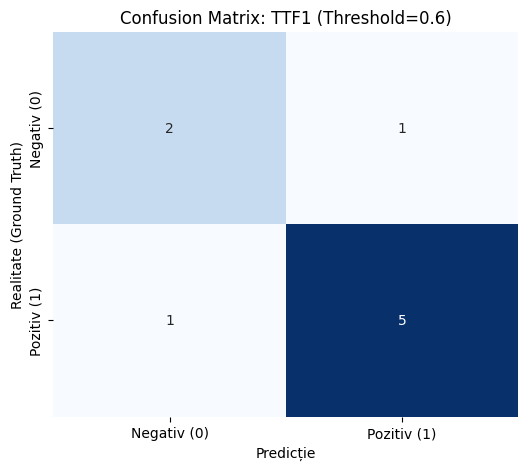

[TTF1] Acc: 0.7778 | F1: 0.8333


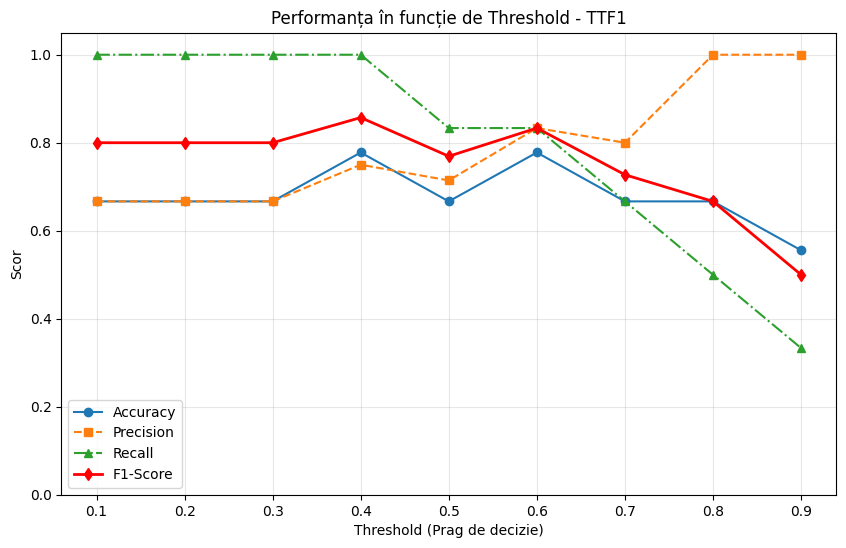


--------------------------------------------------

>>> ANALIZĂ CK7


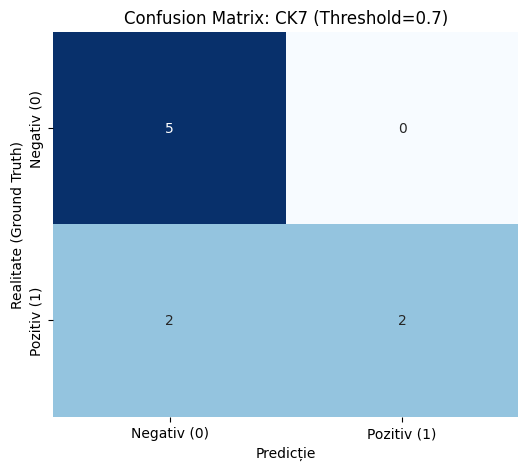

[CK7] Acc: 0.7778 | F1: 0.6667


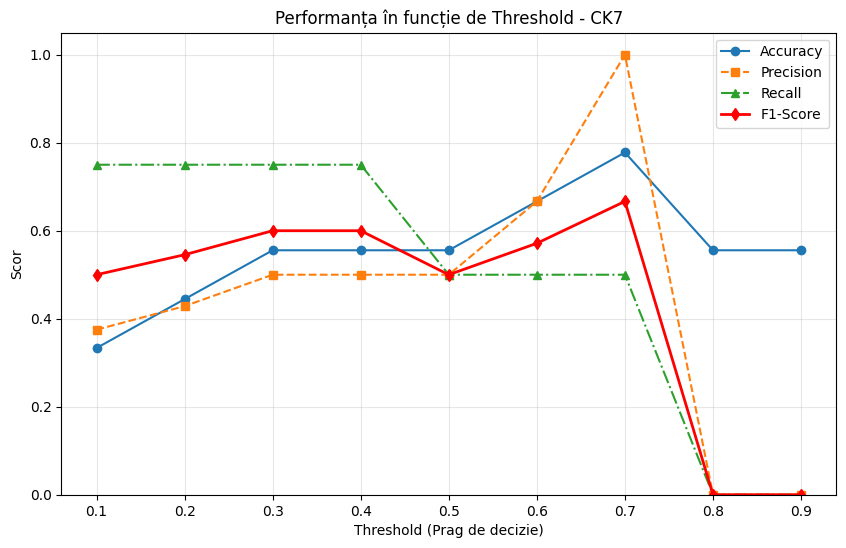

In [ ]:
test(model_finetune)

In [ ]:

BASE_DIR = r'/content/drive/MyDrive/Colab Notebooks'
FINE_TUNED_V2_PATH = str(BASE_DIR + "/cnn_2d/model_2d_efficientnet_radiomics_finetuned_v2.keras")

print(f"Continuăm antrenarea. Modelul va fi salvat în: {FINE_TUNED_V2_PATH}")

callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(FINE_TUNED_V2_PATH, monitor='val_loss', save_best_only=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, verbose=1)
]
history_v2 = model_finetune.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    steps_per_epoch=TRAIN_STEPS,
    validation_steps=VAL_STEPS,
    callbacks=callbacks_v2
)

Continuăm antrenarea. Modelul va fi salvat în: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned_v2.keras
Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - CK7_acc: 0.7476 - CK7_auc: 0.8336 - CK7_loss: 0.5014 - TTF1_acc: 0.8391 - TTF1_auc: 0.9072 - TTF1_loss: 0.3518 - loss: 1.9364
Epoch 1: val_loss improved from inf to 2.48349, saving model to /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned_v2.keras
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 217ms/step - CK7_acc: 0.7476 - CK7_auc: 0.8336 - CK7_loss: 0.5014 - TTF1_acc: 0.8390 - TTF1_auc: 0.9069 - TTF1_loss: 0.3521 - loss: 1.9367 - val_CK7_acc: 0.5876 - val_CK7_auc: 0.6212 - val_CK7_loss: 0.7144 - val_TTF1_acc: 0.6336 - val_TTF1_auc: 0.5592 - val_TTF1_loss: 0.6879 - val_loss: 2.4835 - learning_rate: 1.0000e-05
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - CK7_acc: 0.7550 - CK7_auc: 0.8438 - CK7_loss: 0.4897 - TTF1_acc: 0.8396 - TTF1_auc: 0.9045 - TTF1_loss: 0.3

EVALUATION ON TEST SET (Patient-Level Aggregation)

>>> ANALIZĂ TTF1


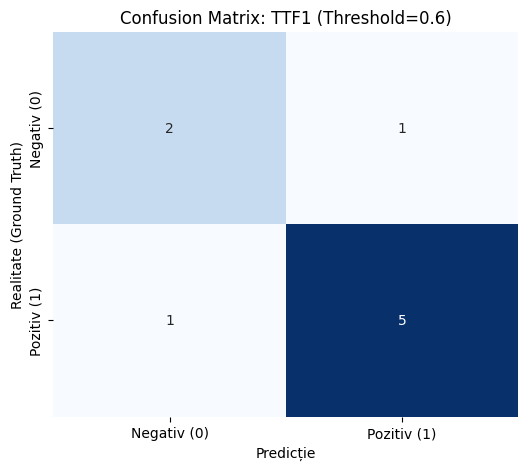

[TTF1] Acc: 0.7778 | F1: 0.8333


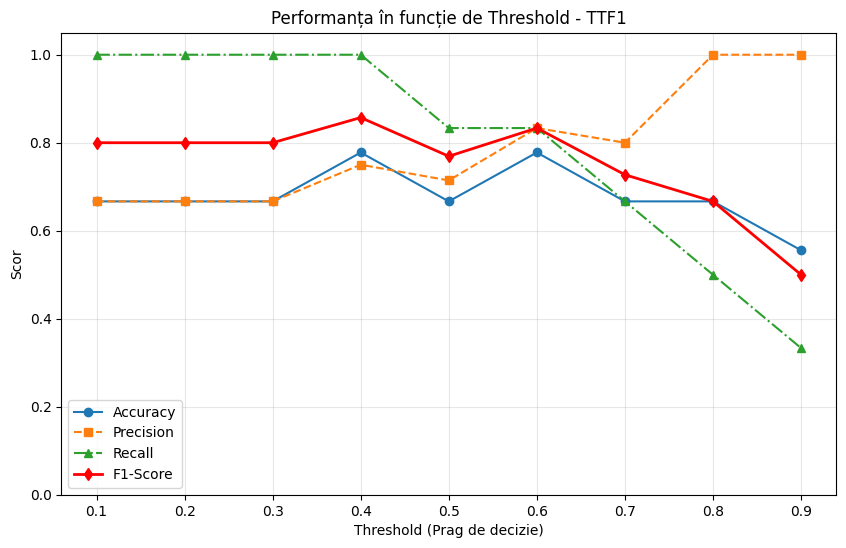


--------------------------------------------------

>>> ANALIZĂ CK7


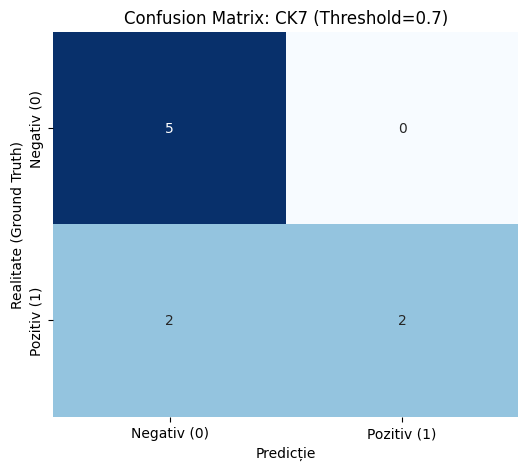

[CK7] Acc: 0.7778 | F1: 0.6667


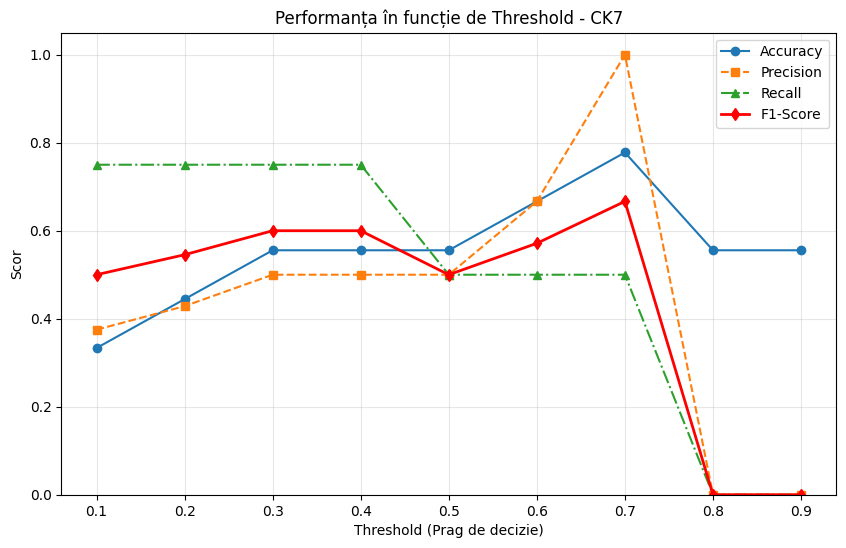

In [ ]:
test(model_finetune)

EVALUATION ON TEST SET (Patient-Level Aggregation)

>>> ANALIZĂ TTF1


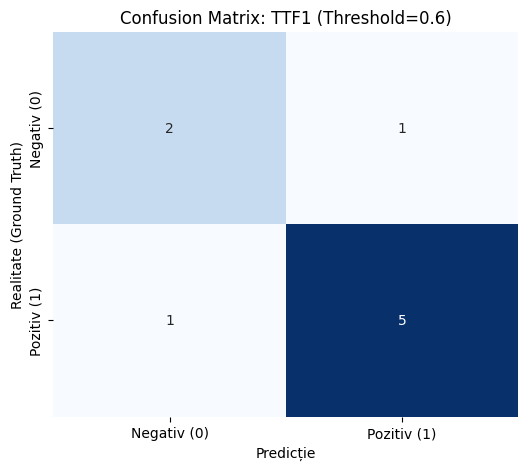

[TTF1] Acc: 0.7778 | F1: 0.8333


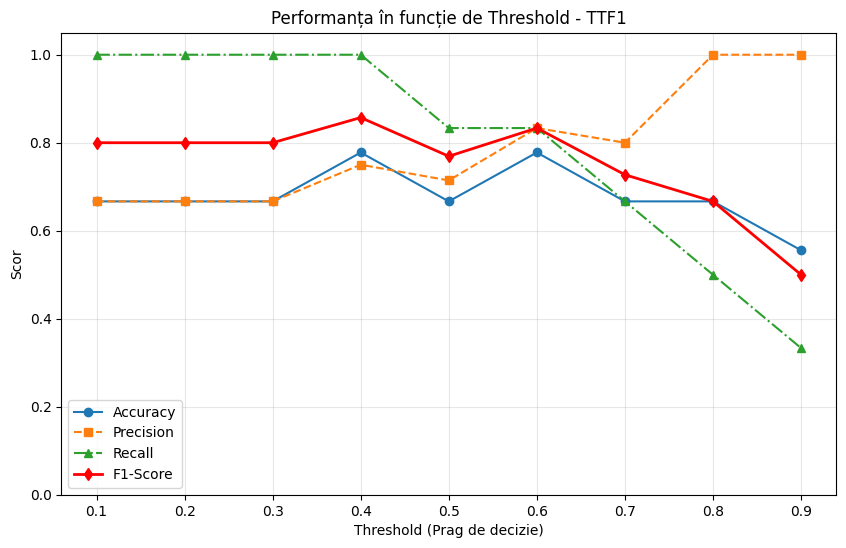


--------------------------------------------------

>>> ANALIZĂ CK7


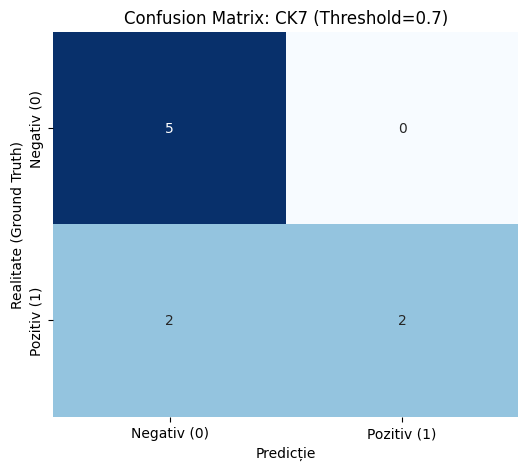

[CK7] Acc: 0.7778 | F1: 0.6667


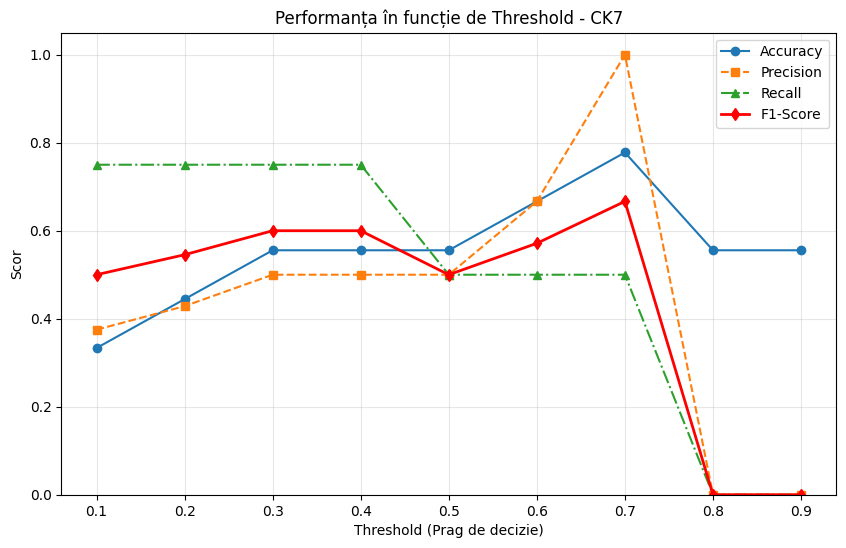


==================== Analiză Erori: TTF1 ====================
Total erori: 2 din 9 pacienți

ID Pacient      | Tip Eroare      | Real  | Pred (Prob)    
------------------------------------------------------------
25111           | False Positive  | 0     | 0.7679
36111           | False Negative  | 1     | 0.4843

==================== Analiză Erori: CK7 ====================
Total erori: 2 din 9 pacienți

ID Pacient      | Tip Eroare      | Real  | Pred (Prob)    
------------------------------------------------------------
33111           | False Negative  | 1     | 0.0188
55011           | False Negative  | 1     | 0.4418


In [ ]:
test(model_finetune)

In [ ]:
MODEL_TO_TEST_PATH = str(BASE_DIR + "/cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras")

print(f"Încărcare model din: {MODEL_TO_TEST_PATH}")

# 2. Încărcăm modelul
try:
    loaded_model = tf.keras.models.load_model(MODEL_TO_TEST_PATH)
    print("Model încărcat cu succes!")
except Exception as e:
    print(f"Eroare la încărcare: {e}")

Încărcare model din: /content/drive/MyDrive/Colab Notebooks/cnn_2d/model_2d_efficientnet_radiomics_finetuned.keras
Model încărcat cu succes!


EVALUATION ON TEST SET (Patient-Level Aggregation)

>>> ANALIZĂ TTF1


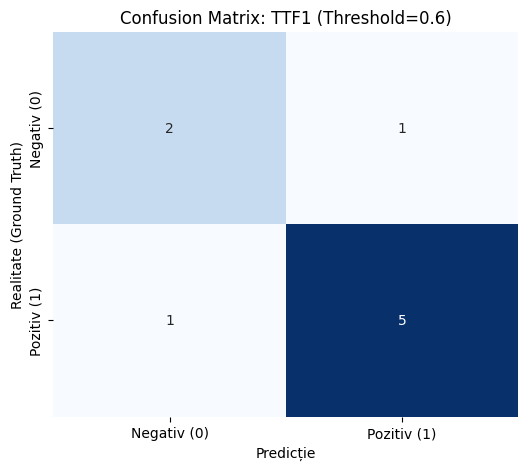

[TTF1] Acc: 0.7778 | F1: 0.8333


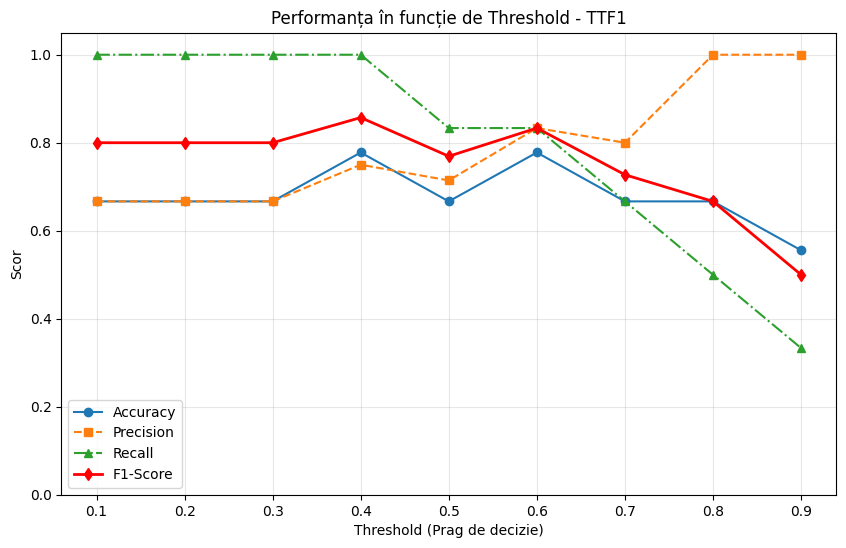


--------------------------------------------------

>>> ANALIZĂ CK7


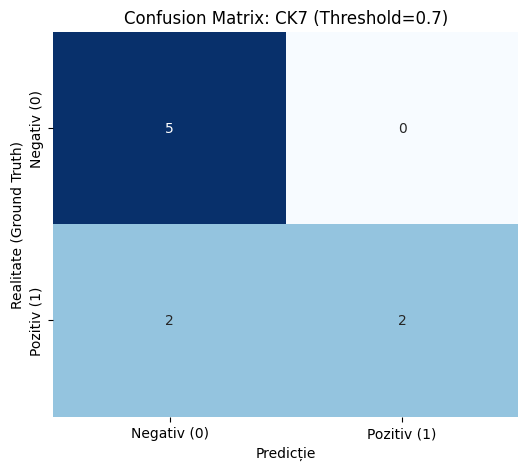

[CK7] Acc: 0.7778 | F1: 0.6667


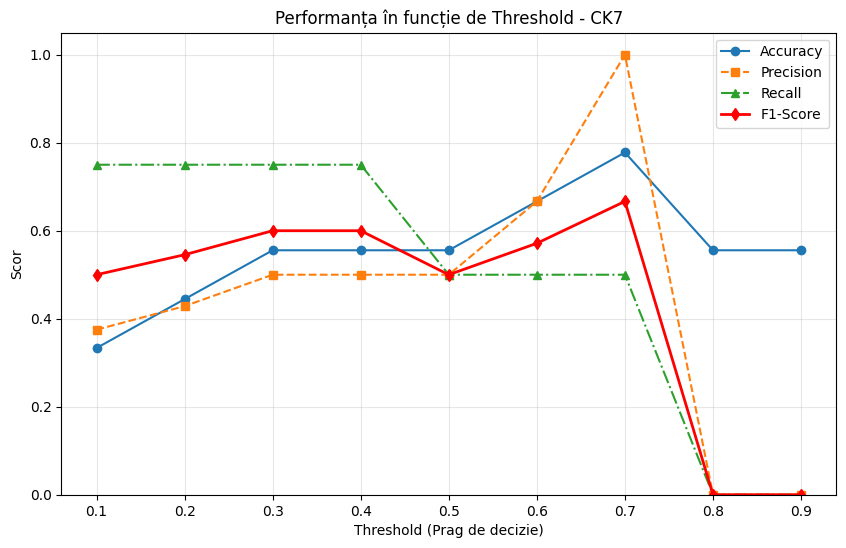


==================== Analiză Erori: TTF1 ====================
Total erori: 2 din 9 pacienți

ID Pacient      | Tip Eroare      | Real  | Pred (Prob)    
------------------------------------------------------------
25111           | False Positive  | 0     | 0.7645
36111           | False Negative  | 1     | 0.4920

==================== Analiză Erori: CK7 ====================
Total erori: 2 din 9 pacienți

ID Pacient      | Tip Eroare      | Real  | Pred (Prob)    
------------------------------------------------------------
33111           | False Negative  | 1     | 0.0214
55011           | False Negative  | 1     | 0.4850


In [ ]:
test(loaded_model)